# Term Project — Part 1
## Multimodal Depression Detection from Acoustic and Linguistic Features
### Dataset Acquisition → Cleaning → Preprocessing → Feature Engineering → EDA

---

**Research question (proposal):** can acoustic and linguistic features from a clinical interview detect depression (binary PHQ-8 ≥ 10), and can a compact, stable feature subset retain the performance of the full feature set?

This notebook is the **first half** of the implementation. It turns the raw DAIC-WOZ interviews into one row of features per participant and explores them. Modeling, fusion, feature-subset search and stability analysis are in Part 2.

### Ground rules used throughout

1. **Participant speech only.** Interviewer (Ellie) turns are removed from the text, and the audio is cut to the participant's own speaking turns. Interviewer prompts are a known shortcut on DAIC-WOZ (Burdisso et al., 2024).
2. **No label leakage.** PHQ-8 scores and item answers are labels, never inputs. Participant IDs and timestamps are never predictors.
3. **The official test split is never used for label-based analysis.** Anything that looks at labels (effect sizes, rankings, class plots) uses the **development pool = train + dev** only, consistent with Part 2.
4. **Nothing is deleted silently.** Missing data and outliers are summarized first; every treatment is justified.
5. **All statements in the observations section are computed from the data in this notebook.**

### Inputs

- Official split files: `train_split_Depression_AVEC2017.csv`, `dev_split_Depression_AVEC2017.csv`, `test_split_Depression_AVEC2017.csv`, `full_test_split.csv`
- One folder per participant `XXX_P/` with audio, transcript, COVAREP, FORMANT and OpenFace (CLNF) files. Locally, `XXX_P.zip` archives are extracted on first run.

### Outputs (`part1_outputs/`)

- `features_master.csv` — participant-level hand-crafted feature matrix (acoustic + linguistic + supplementary video)
- `qc_per_participant.csv`, `outlier_summary.csv`, `feature_ranking_devpool.csv`, `eda_summary.csv`
- `figures/*.png`

## 0. Environment

In [1]:
import os, re, sys, json, time, zipfile, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160)
SEED = 42

def ensure(pkg, pip_name=None):
    try:
        __import__(pkg)
    except ImportError:
        print(f"installing {pip_name or pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg])
for p in ["soundfile", "librosa", "opensmile", "joblib"]:
    ensure(p)
import soundfile as sf, librosa, opensmile, joblib

KAGGLE_ROOT = Path("/kaggle/input/datasets/malihashabbir/depressiondata")
ON_KAGGLE = KAGGLE_ROOT.exists()
DATA_ROOT = KAGGLE_ROOT if ON_KAGGLE else Path(os.environ.get("DAIC_ROOT", "D:/DAIC-WOZ"))
OUT_DIR = (Path("/kaggle/working") if ON_KAGGLE else Path(".")) / "part1_outputs"
FIG_DIR, CACHE_DIR = OUT_DIR / "figures", OUT_DIR / "cache" / "participants"
for d in (FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
N_JOBS = int(os.environ.get("N_JOBS", os.cpu_count() or 2))

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | librosa {librosa.__version__} | opensmile {opensmile.__version__}")
print("DATA_ROOT:", DATA_ROOT, "| exists:", DATA_ROOT.exists())
print("OUT_DIR  :", OUT_DIR.resolve(), "| parallel jobs:", N_JOBS)

Python 3.12.0 | pandas 3.1.1 | librosa 1.0.1 | opensmile 2.6.0
DATA_ROOT: D:\DAIC-WOZ | exists: True
OUT_DIR  : C:\Users\HC\Desktop\Zaid\part1_outputs | parallel jobs: 10


## 1. Dataset Acquisition and Inventory

**Source.** DAIC-WOZ (Distress Analysis Interview Corpus – Wizard of Oz), USC Institute for Creative Technologies; the AVEC 2017 depression sub-challenge release. Access requires a signed data-use agreement and the data must not be redistributed.

**What a "row" is.** One participant = one semi-structured interview with a virtual interviewer (Ellie). The participant ID (300–492) is the key that links every file and label.

We first take a read-only inventory: which participants are present, which file types each folder contains, and any unexpected files.

In [2]:
# Locally the corpus arrives as XXX_P.zip archives: extract any archive whose folder does not exist yet
if not ON_KAGGLE:
    zips = sorted(DATA_ROOT.glob("[0-9][0-9][0-9]_P.zip"))
    todo = [z for z in zips if not (DATA_ROOT / z.stem).is_dir()]
    for z in todo:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(DATA_ROOT / z.stem)
    print(f"{len(zips)} participant archives found, {len(todo)} extracted now")

folders = sorted(p for p in DATA_ROOT.iterdir() if p.is_dir() and re.fullmatch(r"\d{3}_P", p.name))
present_ids = [int(p.name[:3]) for p in folders]
print(f"Participant folders: {len(folders)}  (IDs {min(present_ids)}–{max(present_ids)})")
print("IDs absent from the 300–492 range:", sorted(set(range(300, 493)) - set(present_ids)))

EXPECTED = {"AUDIO.wav", "TRANSCRIPT.csv", "COVAREP.csv", "FORMANT.csv",
            "CLNF_AUs.txt", "CLNF_features.txt", "CLNF_features3D.txt", "CLNF_gaze.txt", "CLNF_pose.txt"}
inv_rows, unexpected = [], []
for f in folders:
    pid = f.name[:3]
    names = [x.name for x in f.iterdir() if x.is_file()]
    types = {n[len(pid) + 1:] for n in names if n.startswith(pid + "_")}
    for n in names:
        if n.startswith(".") or n.startswith("._") or not n.startswith(pid + "_") or n[len(pid) + 1:] not in EXPECTED:
            unexpected.append({"participant_id": int(pid), "file": n, "size_kb": round((f / n).stat().st_size / 1024, 1)})
    inv_rows.append({"participant_id": int(pid), **{t: (t in types) for t in sorted(EXPECTED)},
                     "size_mb": round(sum((f / n).stat().st_size for n in names) / 1e6, 1)})
inventory = pd.DataFrame(inv_rows).set_index("participant_id")
print("\nFolders containing each expected file type:")
display(inventory[sorted(EXPECTED)].sum().to_frame("folders").T)
print("Unexpected / junk files:", "none" if not unexpected else "")
if unexpected:
    display(pd.DataFrame(unexpected))

188 participant archives found, 85 extracted now
Participant folders: 188  (IDs 300–492)
IDs absent from the 300–492 range: [342, 394, 398, 440, 460]



Folders containing each expected file type:


,AUDIO.wav,CLNF_AUs.txt,CLNF_features.txt,CLNF_features3D.txt,CLNF_gaze.txt,CLNF_pose.txt,COVAREP.csv,FORMANT.csv,TRANSCRIPT.csv
folders,188,188,188,188,188,188,188,188,188


Unexpected / junk files: 


,participant_id,file,size_kb
0,300,300_CLNF_hog.txt,339602.9
1,487,._487_TRANSCRIPT.csv,4.0


In [3]:
top_csv = sorted(DATA_ROOT.glob("*.csv"))
top = pd.DataFrame([{"file": p.name, "size_kb": round(p.stat().st_size / 1024, 1)} for p in top_csv])
top["kind"] = np.where(top["file"].str.contains("split"), "official split / labels", "derived feature table (pre-computed)")
display(top)

,file,size_kb,kind
0,DAIC_WOZ_linguistic_features_12.csv,29.6,derived feature table (pre-computed)
1,DAIC_WOZ_MentalBERT_1536.csv,5600.6,derived feature table (pre-computed)
2,DAIC_WOZ_video_temporal_348.csv,1187.8,derived feature table (pre-computed)
3,DAIC_WOZ_wav2vec2_temporal_1536.csv,3202.8,derived feature table (pre-computed)
4,dev_split_Depression_AVEC2017.csv,1.1,official split / labels
5,full_test_split.csv,0.6,official split / labels
6,test_split_Depression_AVEC2017.csv,0.3,official split / labels
7,train_split_Depression_AVEC2017.csv,3.0,official split / labels


## 2. Labels, Target Definition and Splits

The target is **depressed = PHQ-8 total score ≥ 10**. We check that the provided binary column agrees with that rule rather than trusting it, and we check every label file for missing values, duplicates and overlap between splits.

In [4]:
def read_split(name, id_col, bin_col=None, score_col=None):
    df = pd.read_csv(DATA_ROOT / name)
    out = pd.DataFrame({"participant_id": df[id_col].astype(int)})
    if bin_col:
        out["phq_binary"], out["phq_score"] = df[bin_col], df[score_col]
    out["gender"] = df["Gender"]
    return df, out

tr_raw, tr = read_split("train_split_Depression_AVEC2017.csv", "Participant_ID", "PHQ8_Binary", "PHQ8_Score")
dv_raw, dv = read_split("dev_split_Depression_AVEC2017.csv", "Participant_ID", "PHQ8_Binary", "PHQ8_Score")
te_raw, te = read_split("test_split_Depression_AVEC2017.csv", "participant_ID")
ft_raw, ft = read_split("full_test_split.csv", "Participant_ID", "PHQ_Binary", "PHQ_Score")

for name, raw in [("train", tr_raw), ("dev", dv_raw), ("test (official, no labels)", te_raw), ("full_test (test labels)", ft_raw)]:
    na = raw.isna().sum()
    print(f"{name:28s} rows={len(raw):3d} cols={raw.shape[1]:2d}  missing cells: {dict(na[na > 0]) or 'none'}")
print("\nColumns in train:", tr_raw.columns.tolist())

train                        rows=107 cols=12  missing cells: {'PHQ8_Sleep': np.int64(1)}
dev                          rows= 35 cols=12  missing cells: none
test (official, no labels)   rows= 47 cols= 2  missing cells: none
full_test (test labels)      rows= 47 cols= 4  missing cells: none

Columns in train: ['Participant_ID', 'PHQ8_Binary', 'PHQ8_Score', 'Gender', 'PHQ8_NoInterest', 'PHQ8_Depressed', 'PHQ8_Sleep', 'PHQ8_Tired', 'PHQ8_Appetite', 'PHQ8_Failure', 'PHQ8_Concentrating', 'PHQ8_Moving']


In [5]:
# Target check: does the provided binary label equal (score >= 10)?
mismatch = []
for name, df in [("train", tr), ("dev", dv), ("test", ft)]:
    derived = (df["phq_score"] >= 10).astype(int)
    bad = df[df["phq_binary"] != derived]
    mismatch += [{"split": name, **r} for r in bad[["participant_id", "phq_score", "phq_binary"]].to_dict("records")]
    print(f"{name:5s}: label missing={df['phq_binary'].isna().sum()}, score missing={df['phq_score'].isna().sum()}, "
          f"binary ≠ (score ≥ 10) in {len(bad)} rows")
if mismatch:
    print("\nRows where the official binary label disagrees with PHQ-8 ≥ 10:")
    display(pd.DataFrame(mismatch))

# Does the total score equal the sum of the eight item answers?
items = [c for c in tr_raw.columns if c.startswith("PHQ8_") and c not in ("PHQ8_Binary", "PHQ8_Score")]
for name, raw in [("train", tr_raw), ("dev", dv_raw)]:
    s = raw[items].sum(axis=1, min_count=1)
    bad = raw[(s != raw["PHQ8_Score"]) | raw[items].isna().any(axis=1)]
    print(f"{name}: rows where score ≠ item sum or an item is missing:",
          bad[["Participant_ID", "PHQ8_Score"] + items].to_dict("records") or "none")

# test IDs/gender must agree between the official test file and full_test
assert set(te["participant_id"]) == set(ft["participant_id"])
ft = ft.merge(te[["participant_id"]], on="participant_id")

labels = pd.concat([tr.assign(split="train"), dv.assign(split="dev"), ft.assign(split="test")], ignore_index=True)
print("\nDuplicate participant IDs across all label files:", labels["participant_id"].duplicated().sum())
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    print(f"  overlap {a} ∩ {b}: {len(set(labels.query('split == @a').participant_id) & set(labels.query('split == @b').participant_id))}")

train: label missing=0, score missing=0, binary ≠ (score ≥ 10) in 1 rows
dev  : label missing=0, score missing=0, binary ≠ (score ≥ 10) in 0 rows
test : label missing=0, score missing=0, binary ≠ (score ≥ 10) in 0 rows

Rows where the official binary label disagrees with PHQ-8 ≥ 10:


,split,participant_id,phq_score,phq_binary
0,train,409,10,0


train: rows where score ≠ item sum or an item is missing: [{'Participant_ID': 319, 'PHQ8_Score': 13, 'PHQ8_NoInterest': 2, 'PHQ8_Depressed': 1, 'PHQ8_Sleep': nan, 'PHQ8_Tired': 1, 'PHQ8_Appetite': 1, 'PHQ8_Failure': 2, 'PHQ8_Concentrating': 3, 'PHQ8_Moving': 1}]
dev: rows where score ≠ item sum or an item is missing: none

Duplicate participant IDs across all label files: 0
  overlap train ∩ dev: 0
  overlap train ∩ test: 0
  overlap dev ∩ test: 0


**Label decision.** One training participant (409) has a PHQ-8 score of exactly 10 but an official binary label of 0, so the official label breaks the ≥ 10 rule in one case. We **keep the official AVEC 2017 labels** as the target: they are the benchmark labels used by published DAIC-WOZ work, so our results stay comparable. This one case is reported, not silently changed. A missing item answer (participant 319, sleep item) does not matter because only the total score and binary label are used, and the total is complete.

In [6]:
# Participants listed in a split but without a data folder cannot be used
labels["has_data"] = labels["participant_id"].isin(present_ids)
excluded = labels[~labels["has_data"]]
print("Listed in a split but no data folder:", excluded[["participant_id", "split", "phq_binary"]].to_dict("records") or "none")
print("Data folder but not in any split:", sorted(set(present_ids) - set(labels["participant_id"])) or "none")

labels = labels[labels["has_data"]].drop(columns="has_data").set_index("participant_id").sort_index()
labels["phq_binary"] = labels["phq_binary"].astype(int)
labels["pool"] = np.where(labels["split"] == "test", "test", "dev pool")
DEVPOOL = labels.index[labels["pool"] == "dev pool"]

tab = labels.groupby("split")["phq_binary"].agg(participants="size", depressed="sum").loc[["train", "dev", "test"]]
tab["not_depressed"] = tab["participants"] - tab["depressed"]
tab["% depressed"] = (100 * tab["depressed"] / tab["participants"]).round(1)
display(tab)
print(f"Participants used: {len(labels)}  (development pool = train+dev: {len(DEVPOOL)}, test: {(labels.pool == 'test').sum()})")
print("PHQ-8 item columns (PHQ8_NoInterest … PHQ8_Moving) are part of the label definition and are never used as inputs.")

Listed in a split but no data folder: [{'participant_id': 440, 'split': 'dev', 'phq_binary': 1}]
Data folder but not in any split: none


,participants,depressed,not_depressed,% depressed
split,,,,
train,107,30,77,28.0
dev,34,11,23,32.4
test,47,14,33,29.8


Participants used: 188  (development pool = train+dev: 141, test: 47)
PHQ-8 item columns (PHQ8_NoInterest … PHQ8_Moving) are part of the label definition and are never used as inputs.


### 2.1 Pre-computed feature tables

The data folder also contains participant-level tables produced earlier (wav2vec2 / MentalBERT embeddings, video and linguistic summaries). Their exact extraction code is not part of this notebook, so we only **describe and validate** them here (IDs, missing values, duplicates). Part 2 uses the embedding tables; everything analysed in this notebook is computed from the raw files below.

In [7]:
rows = []
for p in top_csv:
    if "split" in p.name:
        continue
    df = pd.read_csv(p)
    idc = next((c for c in df.columns if c.lower() in ("participant_id", "participant", "id")), None)
    ids = set(df[idc]) if idc else set()
    rows.append({"file": p.name, "rows": len(df), "columns": df.shape[1], "id_column": idc,
                 "missing_cells": int(df.isna().sum().sum()), "duplicate_ids": int(df[idc].duplicated().sum()) if idc else None,
                 "ids_match_participants_used": ids == set(labels.index) if idc else None})
display(pd.DataFrame(rows))

,file,rows,columns,id_column,missing_cells,duplicate_ids,ids_match_participants_used
0,DAIC_WOZ_linguistic_features_12.csv,188,14,participant_id,0,0,True
1,DAIC_WOZ_MentalBERT_1536.csv,188,1538,participant_id,0,0,True
2,DAIC_WOZ_video_temporal_348.csv,188,350,participant_id,0,0,True
3,DAIC_WOZ_wav2vec2_temporal_1536.csv,188,1538,participant_id,0,0,True


## 3. Inspecting the Raw Files

Before aggregating anything we look at the actual structure of each file type (one participant shown; the checks in Section 4 run on every participant).

In [8]:
pid0 = int(labels.index[0])
P0 = DATA_ROOT / f"{pid0}_P"
t0 = pd.read_csv(P0 / f"{pid0}_TRANSCRIPT.csv", sep="\t")
print(f"TRANSCRIPT ({pid0}): columns={t0.columns.tolist()}, rows={len(t0)}, speakers={t0['speaker'].value_counts().to_dict()}")
display(t0.head(4))

cov0 = pd.read_csv(P0 / f"{pid0}_COVAREP.csv", header=None)
fmt0 = pd.read_csv(P0 / f"{pid0}_FORMANT.csv", header=None)
print(f"COVAREP: {cov0.shape} (no header, 1 row per 10 ms) | FORMANT: {fmt0.shape}")
info = sf.info(P0 / f"{pid0}_AUDIO.wav")
print(f"AUDIO: {info.samplerate} Hz, {info.channels} channel(s), {info.duration / 60:.1f} min, {info.subtype}")
for kind in ["AUs", "pose", "gaze"]:
    of = pd.read_csv(P0 / f"{pid0}_CLNF_{kind}.txt", skipinitialspace=True, nrows=3)
    print(f"CLNF_{kind}: columns = {of.columns.tolist()}")

TRANSCRIPT (300): columns=['start_time', 'stop_time', 'speaker', 'value'], rows=174, speakers={'Ellie': 87, 'Participant': 87}


,start_time,stop_time,speaker,value
0,36.588,39.668,Ellie,hi i'm ellie thanks for coming in today
1,39.888,43.378,Ellie,i was created to talk to people in a safe and ...
2,43.728,48.498,Ellie,think of me as a friend i don't judge i can't ...
3,49.188,52.388,Ellie,i'm here to learn about people and would love ...


COVAREP: (64851, 74) (no header, 1 row per 10 ms) | FORMANT: (64850, 5)
AUDIO: 16000 Hz, 1 channel(s), 10.8 min, PCM_16
CLNF_AUs: columns = ['frame', 'timestamp', 'confidence', 'success', 'AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU09_r', 'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU25_r', 'AU26_r', 'AU04_c', 'AU12_c', 'AU15_c', 'AU23_c', 'AU28_c', 'AU45_c']
CLNF_pose: columns = ['frame', 'timestamp', 'confidence', 'success', 'Tx', 'Ty', 'Tz', 'Rx', 'Ry', 'Rz']
CLNF_gaze: columns = ['frame', 'timestamp', 'confidence', 'success', 'x_0', 'y_0', 'z_0', 'x_1', 'y_1', 'z_1', 'x_h0', 'y_h0', 'z_h0', 'x_h1', 'y_h1', 'z_h1']


**What these files are**

| File | Rate | Content | How we use it |
|---|---|---|---|
| `TRANSCRIPT.csv` | per turn | `start_time`, `stop_time`, `speaker` (Ellie / Participant), `value` (text) | participant turns only → text features, turn timing, and the time segments used to cut the audio |
| `AUDIO.wav` | 16 kHz | full interview recording | cut to participant turns → eGeMAPS (openSMILE) and MFCCs |
| `COVAREP.csv` | 100 Hz | 74 columns, no header. Per the COVAREP feature list: F0, VUV (voiced flag), NAQ, QOQ, H1H2, PSP, MDQ, peakSlope, Rd, Rd_conf, creak, MCEP 0–24, HMPDM 0–24, HMPDD 0–12 | voiced frames inside participant turns → voice-quality statistics |
| `FORMANT.csv` | 100 Hz | F1–F5 (Hz) | F1–F3 on the same voiced frames |
| `CLNF_*.txt` | 30 fps | OpenFace output. `frame, timestamp, confidence, success` are **tracking metadata**, not predictors | supplementary video block: tracking quality first, then successful frames only |

`CLNF_features.txt` / `CLNF_features3D.txt` hold raw 2-D/3-D landmark coordinates. They depend on camera placement and head position rather than behaviour, so we do not aggregate them; facial behaviour is represented by action units, head pose and gaze.

## 4. Preprocessing and Feature Extraction (one row per participant)

For every participant:

1. **Transcript.** Keep `Participant` turns; strip annotation tokens such as `<laughter>` (counted separately); lower-case; tokenize.
2. **Turn timing.** Speaking time, number of turns, speaking rate, and **response latency** (gap between the end of Ellie's turn and the start of the participant's reply — a pause/psychomotor measure).
3. **Audio.** Concatenate the participant's turn segments from `AUDIO.wav` (removes Ellie's voice and the silence before/after the interview) → **eGeMAPS v02** functionals (88 features: pitch, loudness, jitter, shimmer, HNR, formants, spectral slope, voiced/unvoiced segment statistics) and **MFCC 1–13** mean/std.
4. **COVAREP / FORMANT.** Keep frames inside participant turns *and* marked voiced (`VUV = 1`); unvoiced frames have F0 = 0 and would bias pitch statistics. Mean and std of each voice-quality parameter and of F1–F3.
5. **OpenFace (supplementary).** Report tracking success and confidence; aggregate action-unit intensities, head pose and gaze over **successful frames only** (failed frames contain zeros, not measurements).

Each participant's result is cached, so the slow step (≈1 min per participant for eGeMAPS) runs only once and can be resumed.

In [9]:
COVAREP_COLS = (["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd", "Rd_conf", "creak"]
                + [f"MCEP_{i}" for i in range(25)] + [f"HMPDM_{i}" for i in range(25)] + [f"HMPDD_{i}" for i in range(13)])
assert len(COVAREP_COLS) == 74
VOICE_Q = ["F0", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd", "creak"]

LEX = {
    "negation":   {"not", "no", "never", "none", "nobody", "nothing", "neither", "nowhere", "cannot", "can't", "don't",
                   "doesn't", "didn't", "won't", "wouldn't", "shouldn't", "isn't", "aren't", "wasn't", "weren't"},
    "absolutist": {"always", "never", "completely", "totally", "absolutely", "entirely", "every", "all", "nothing",
                   "constant", "constantly", "definitely", "everything", "whole"},
    "i_words":    {"i", "me", "my", "mine", "myself", "i'm", "i've", "i'd", "i'll"},
    "we_words":   {"we", "us", "our", "ours", "ourselves", "we're", "we've"},
    "neg_emotion": {"sad", "depressed", "depression", "hopeless", "worthless", "lonely", "empty", "miserable", "unhappy",
                    "tired", "exhausted", "cry", "crying", "hurt", "pain", "angry", "mad", "upset", "worried", "anxious",
                    "afraid", "scared", "fear", "stress", "stressed", "overwhelmed", "bad", "hate", "awful", "terrible"},
    "pos_emotion": {"happy", "good", "great", "love", "enjoy", "fun", "joy", "excited", "glad", "pleased", "better",
                    "positive", "hope", "hopeful", "proud", "nice", "wonderful", "awesome", "best"},
    "anxiety":    {"anxious", "anxiety", "worried", "worry", "nervous", "tense", "panic", "afraid", "scared", "fear",
                   "stress", "stressed", "overwhelmed"},
    "fillers":    {"um", "uh", "hmm", "mm", "er", "ah"},
}
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")
ANNOT_RE = re.compile(r"<[^>]*>|\[[^\]]*\]")

def text_and_timing(pid):
    t = pd.read_csv(DATA_ROOT / f"{pid}_P" / f"{pid}_TRANSCRIPT.csv", sep="\t")
    t.columns = [c.strip().lower() for c in t.columns]
    t["speaker"] = t["speaker"].astype(str).str.strip().str.lower()
    t["value"] = t["value"].fillna("").astype(str)
    t = t.sort_values("start_time").reset_index(drop=True)
    is_p = t["speaker"] == "participant"
    p = t[is_p].copy()
    p["n_annot"] = p["value"].str.count(ANNOT_RE)
    p["clean"] = p["value"].str.lower().str.replace(ANNOT_RE, " ", regex=True)
    p["tokens"] = p["clean"].map(TOKEN_RE.findall)
    p["n_words"] = p["tokens"].map(len)
    p["dur"] = (p["stop_time"] - p["start_time"]).clip(lower=0)

    # response latency: participant turn that directly follows an Ellie turn
    prev_spk, prev_stop = t["speaker"].shift(), t["stop_time"].shift()
    lat = (t["start_time"] - prev_stop)[is_p & (prev_spk == "ellie")]
    lat = lat[(lat >= 0) & (lat <= 30)]          # negative = overlap; >30 s = recording gap

    tokens = [w for ws in p["tokens"] for w in ws]
    nw, wpt = len(tokens), p["n_words"].values
    speak = p["dur"].sum()
    f = {
        "tm_n_turns": len(p), "tm_speaking_time_s": speak, "tm_interview_length_s": t["stop_time"].max() - t["start_time"].min(),
        "tm_speaking_share": speak / max(t["stop_time"].max() - t["start_time"].min(), 1e-9),
        "tm_turn_dur_mean_s": p["dur"].mean(), "tm_turn_dur_median_s": p["dur"].median(),
        "tm_speech_rate_wps": nw / max(speak, 1e-9),
        "tm_latency_mean_s": lat.mean(), "tm_latency_median_s": lat.median(), "tm_latency_std_s": lat.std(),
        "tx_word_count": nw, "tx_vocab_size": len(set(tokens)), "tx_type_token_ratio": len(set(tokens)) / max(nw, 1),
        "tx_mean_word_len": float(np.mean([len(w) for w in tokens])) if tokens else np.nan,
        "tx_words_per_turn_mean": wpt.mean(), "tx_words_per_turn_median": float(np.median(wpt)), "tx_words_per_turn_std": wpt.std(),
        "tx_one_word_turn_ratio": float((wpt == 1).mean()), "tx_short_turn_ratio": float((wpt <= 3).mean()),
        "tx_long_turn_ratio": float((wpt >= 20).mean()), "tx_annotations_per_turn": p["n_annot"].mean(),
    }
    for k, ws in LEX.items():
        f[f"tx_{k}_per100"] = 100 * sum(w in ws for w in tokens) / max(nw, 1)
    segs = p.loc[p["dur"] > 0, ["start_time", "stop_time"]].values
    qc = {"transcript_rows": len(t), "participant_turns": len(p), "ellie_turns": int((t["speaker"] == "ellie").sum()),
          "other_speaker_rows": int((~t["speaker"].isin(["ellie", "participant"])).sum()), "empty_participant_turns": int((p["n_words"] == 0).sum())}
    return f, qc, segs

def in_segments(times, segs):
    idx = np.searchsorted(segs[:, 0], times, side="right") - 1
    ok = idx >= 0
    ok[ok] = times[ok] <= segs[idx[ok], 1]
    return ok

_SMILE = None
def acoustic(pid, segs):
    global _SMILE
    if _SMILE is None:
        _SMILE = opensmile.Smile(feature_set=opensmile.FeatureSet.eGeMAPSv02, feature_level=opensmile.FeatureLevel.Functionals)
    y, sr = sf.read(DATA_ROOT / f"{pid}_P" / f"{pid}_AUDIO.wav", dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    parts = [y[int(a * sr):int(b * sr)] for a, b in segs]
    sig = np.concatenate([s for s in parts if len(s)]) if parts else np.zeros(sr, dtype="float32")
    f = {f"eg_{k}": float(v) for k, v in _SMILE.process_signal(sig, sr).iloc[0].items()}
    mf = librosa.feature.mfcc(y=sig, sr=sr, n_mfcc=13)
    for i in range(13):
        f[f"mfcc{i + 1}_mean"], f[f"mfcc{i + 1}_std"] = float(mf[i].mean()), float(mf[i].std())
    qc = {"audio_sr": sr, "audio_total_s": len(y) / sr, "audio_participant_s": len(sig) / sr,
          "audio_clipped_frac": float((np.abs(y) >= 0.999).mean())}
    return f, qc

def covarep_formant(pid, segs):
    d = DATA_ROOT / f"{pid}_P"
    cov = pd.read_csv(d / f"{pid}_COVAREP.csv", header=None).apply(pd.to_numeric, errors="coerce")
    fmt = pd.read_csv(d / f"{pid}_FORMANT.csv", header=None).apply(pd.to_numeric, errors="coerce")
    qc = {"covarep_frames": len(cov), "covarep_cols": cov.shape[1], "covarep_nonnumeric": int(cov.isna().sum().sum()),
          "formant_frames": len(fmt), "formant_nonnumeric": int(fmt.isna().sum().sum())}
    cov.columns = COVAREP_COLS[:cov.shape[1]]
    n = min(len(cov), len(fmt))
    cov, fmt = cov.iloc[:n], fmt.iloc[:n]
    t = np.arange(n) / 100.0
    in_p = in_segments(t, segs) if len(segs) else np.zeros(n, bool)
    voiced = in_p & (cov["VUV"].values == 1)
    qc["participant_frames"], qc["participant_voiced_frames"] = int(in_p.sum()), int(voiced.sum())
    f = {"cov_voiced_ratio": voiced.sum() / max(in_p.sum(), 1)}
    v = cov.loc[voiced, VOICE_Q]
    for c in VOICE_Q:
        f[f"cov_{c}_mean"], f[f"cov_{c}_std"] = v[c].mean(), v[c].std()
    for j in range(3):
        fj = fmt.iloc[:, j][voiced]
        fj = fj[fj > 0]
        f[f"fmt_F{j + 1}_mean"], f[f"fmt_F{j + 1}_std"] = fj.mean(), fj.std()
    return f, qc

def video(pid):
    d = DATA_ROOT / f"{pid}_P"
    f, qc = {}, {}
    for kind, prefix, keep in [("AUs", "vid_au", r"AU\d+_r"), ("pose", "vid_pose", r"[TR][xyz]"), ("gaze", "vid_gaze", r"[xyz]_[01]$")]:
        df = pd.read_csv(d / f"{pid}_CLNF_{kind}.txt", skipinitialspace=True)
        df.columns = [c.strip() for c in df.columns]
        df = df.apply(pd.to_numeric, errors="coerce")
        if kind == "AUs":
            qc.update({"video_frames": len(df), "video_success_rate": df["success"].mean(),
                       "video_confidence_median": df["confidence"].median(), "video_nonnumeric": int(df.isna().sum().sum())})
        ok = df[(df["success"] == 1)]
        for c in [c for c in df.columns if re.fullmatch(keep, c)]:
            f[f"{prefix}_{c}_mean"], f[f"{prefix}_{c}_std"] = ok[c].mean(), ok[c].std()
    return f, qc

def extract(pid):
    cache = CACHE_DIR / f"{pid}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    t0 = time.time()
    feats, qc = {}, {"participant_id": int(pid)}
    ft_, q, segs = text_and_timing(pid); feats.update(ft_); qc.update(q)
    fa, q = acoustic(pid, segs); feats.update(fa); qc.update(q)
    fc, q = covarep_formant(pid, segs); feats.update(fc); qc.update(q)
    fv, q = video(pid); feats.update(fv); qc.update(q)
    qc["extract_seconds"] = round(time.time() - t0, 1)
    out = {"features": {k: (None if pd.isna(v) else float(v)) for k, v in feats.items()}, "qc": qc}
    cache.write_text(json.dumps(out))
    return out

In [10]:
ids = list(labels.index)
todo = [p for p in ids if not (CACHE_DIR / f"{p}.json").exists()]
print(f"{len(ids)} participants, {len(ids) - len(todo)} cached, {len(todo)} to extract with {N_JOBS} workers ...")
t0 = time.time()
if todo:
    joblib.Parallel(n_jobs=N_JOBS, verbose=5)(joblib.delayed(extract)(p) for p in todo)
res = {p: extract(p) for p in ids}
print(f"done in {(time.time() - t0) / 60:.1f} min")

features = pd.DataFrame({p: r["features"] for p, r in res.items()}).T.astype(float)
features.index.name = "participant_id"
qc = pd.DataFrame([r["qc"] for r in res.values()]).set_index("participant_id")
qc.to_csv(OUT_DIR / "qc_per_participant.csv")

BLOCKS = {
    "acoustic: eGeMAPS":        [c for c in features if c.startswith("eg_")],
    "acoustic: MFCC":           [c for c in features if c.startswith("mfcc")],
    "acoustic: COVAREP voice":  [c for c in features if c.startswith("cov_")],
    "acoustic: formants":       [c for c in features if c.startswith("fmt_")],
    "timing (turns, pauses)":   [c for c in features if c.startswith("tm_")],
    "linguistic":               [c for c in features if c.startswith("tx_")],
    "video (supplementary)":    [c for c in features if c.startswith("vid_")],
}
display(pd.Series({k: len(v) for k, v in BLOCKS.items()}, name="features").to_frame())
print("Feature matrix:", features.shape)

188 participants, 103 cached, 85 to extract with 10 workers ...


[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.


[Parallel(n_jobs=10)]: Done  52 tasks      | elapsed:  2.8min


[Parallel(n_jobs=10)]: Done  85 out of  85 | elapsed:  4.0min finished


done in 4.1 min


,features
acoustic: eGeMAPS,88
acoustic: MFCC,26
acoustic: COVAREP voice,19
acoustic: formants,6
"timing (turns, pauses)",10
linguistic,19
video (supplementary),52


Feature matrix: (188, 220)


### 4.1 Quality checks from extraction (all participants)

In [11]:
qc_view = qc[["participant_turns", "ellie_turns", "other_speaker_rows", "empty_participant_turns", "audio_total_s", "audio_participant_s",
              "audio_clipped_frac", "covarep_frames", "covarep_cols", "covarep_nonnumeric", "formant_nonnumeric",
              "participant_voiced_frames", "video_success_rate", "video_confidence_median", "video_nonnumeric"]]
display(qc_view.describe().T[["min", "50%", "max"]].round(3))

print("Participants with transcript rows from speakers other than Ellie/Participant:", int((qc["other_speaker_rows"] > 0).sum()))
print("COVAREP files not 74 columns:", int((qc["covarep_cols"] != 74).sum()), "| non-numeric COVAREP cells (all files):", int(qc["covarep_nonnumeric"].sum()))
print("COVAREP vs FORMANT frame-count difference (max):", int((qc["covarep_frames"] - qc["formant_frames"]).abs().max()))
low_track = qc[qc["video_success_rate"] < 0.8]
print(f"Participants with OpenFace success < 80% of frames: {len(low_track)}",
      low_track["video_success_rate"].round(2).to_dict() if len(low_track) else "")

,min,50%,max
participant_turns,42.000,154.500,386.000
ellie_turns,0.000,80.000,121.000
other_speaker_rows,0.000,0.000,0.000
empty_participant_turns,0.000,3.000,33.000
audio_total_s,414.800,911.050,1966.200
audio_participant_s,62.230,426.705,1282.820
audio_clipped_frac,0.000,0.000,0.000
covarep_frames,41481.000,91105.500,196620.000
covarep_cols,74.000,74.000,74.000
covarep_nonnumeric,0.000,0.000,0.000


Participants with transcript rows from speakers other than Ellie/Participant: 0
COVAREP files not 74 columns: 0 | non-numeric COVAREP cells (all files): 0
COVAREP vs FORMANT frame-count difference (max): 1
Participants with OpenFace success < 80% of frames: 4 {344: 0.79, 389: 0.78, 418: 0.74, 432: 0.75}


## 5. Data Cleaning (participant-level table)

### 5.1 Missing values

In [12]:
miss = features.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print(f"Columns with missing values: {len(miss)} of {features.shape[1]}; participants with any missing value: {int(features.isna().any(axis=1).sum())}")
if len(miss):
    display(miss.to_frame("missing participants").head(20))
    for c in miss.index[:5]:
        print(f"  {c}: participants {features.index[features[c].isna()].tolist()[:10]}")

Columns with missing values: 3 of 220; participants with any missing value: 3


,missing participants
tm_latency_mean_s,3
tm_latency_median_s,3
tm_latency_std_s,3


  tm_latency_mean_s: participants [451, 458, 480]
  tm_latency_median_s: participants [451, 458, 480]
  tm_latency_std_s: participants [451, 458, 480]


**Treatment of missing values.** Missing cells here are *structural*, not data-entry errors (for example, latency is undefined when a participant never answers directly after Ellie, and a standard deviation is undefined with fewer than two values). With only ~140 development participants we **do not drop participants**. Imputation is a learned step, so it is **not** done here: Part 2 fits a median imputer inside each training fold. Columns that are missing for more than 20 % of participants are dropped below because they cannot be estimated reliably.

In [13]:
too_sparse = miss[miss > 0.2 * len(features)].index.tolist()
features = features.drop(columns=too_sparse)
print("Dropped (>20% missing):", too_sparse or "none")

Dropped (>20% missing): none


### 5.2 Duplicates and constant columns

In [14]:
print("Duplicate participant IDs:", int(features.index.duplicated().sum()))
print("Identical feature rows (possible duplicated recordings):", int(features.round(6).duplicated().sum()))
const = [c for c in features if features[c].nunique(dropna=True) <= 1]
print("Constant columns:", const or "none")
features = features.drop(columns=const)
dup_cols = features.T.round(8).duplicated()
print("Exactly duplicated columns:", features.columns[dup_cols].tolist() or "none")
features = features.loc[:, ~dup_cols]
print("Matrix after cleaning:", features.shape)

Duplicate participant IDs: 0


Identical feature rows (possible duplicated recordings): 0
Constant columns: ['cov_creak_mean', 'cov_creak_std']
Exactly duplicated columns: none
Matrix after cleaning: (188, 218)


### 5.3 Outliers

We **summarize first**: per feature, the share of participants outside 1.5 × IQR; per participant, how many features have a robust z-score (median/MAD) above 3.5. Then we look at *why* the most extreme participants are extreme before deciding anything.

In [15]:
X = features
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr_out = ((X < q1 - 1.5 * (q3 - q1)) | (X > q3 + 1.5 * (q3 - q1))).mean().sort_values(ascending=False)
mad = (X - X.median()).abs().median().replace(0, np.nan) * 1.4826
rz = ((X - X.median()) / mad).abs()
per_part = (rz > 3.5).sum(axis=1).sort_values(ascending=False)

block_of = {c: b for b, cs in BLOCKS.items() for c in cs}
out_block = iqr_out.groupby(lambda c: block_of.get(c, "other")).mean().sort_values(ascending=False)
print("Mean share of participants outside 1.5×IQR, by block:")
display(out_block.round(3).to_frame("IQR-outlier share"))
print("Features with the highest IQR-outlier share:")
display(iqr_out.head(10).round(3).to_frame("share"))

top_out = per_part.head(8).to_frame("features with |robust z| > 3.5")
top_out = top_out.join(qc[["participant_turns", "audio_participant_s", "video_success_rate"]]).join(labels[["split", "phq_binary"]])
display(top_out)
pd.DataFrame({"iqr_outlier_share": iqr_out}).to_csv(OUT_DIR / "outlier_summary.csv")

Mean share of participants outside 1.5×IQR, by block:


,IQR-outlier share
acoustic: eGeMAPS,0.034
linguistic,0.028
"timing (turns, pauses)",0.026
video (supplementary),0.025
acoustic: COVAREP voice,0.024
acoustic: MFCC,0.017
acoustic: formants,0.012


Features with the highest IQR-outlier share:


,share
eg_mfcc2V_sma3nz_stddevNorm,0.245
eg_slopeV0-500_sma3nz_stddevNorm,0.229
eg_mfcc2_sma3_stddevNorm,0.186
cov_PSP_std,0.133
cov_Rd_std,0.133
eg_mfcc4_sma3_stddevNorm,0.128
eg_mfcc3V_sma3nz_stddevNorm,0.117
eg_spectralFlux_sma3_stddevNorm,0.112
eg_mfcc4V_sma3nz_stddevNorm,0.112
eg_logRelF0-H1-H2_sma3nz_stddevNorm,0.106


,features with |robust z| > 3.5,participant_turns,audio_participant_s,video_success_rate,split,phq_binary
participant_id,,,,,,
308,26,154,326.707063,0.877531,test,1
307,22,186,843.785062,0.887292,dev,0
305,18,288,1118.489937,0.974981,train,0
344,17,169,604.250000,0.791246,train,1
306,13,108,509.370000,0.981471,test,0
309,12,94,182.018063,0.918143,test,1
478,11,152,403.347000,0.956350,train,0
380,10,368,1214.888938,0.891149,train,1


**Treatment of outliers.** Extreme values come mostly from (a) participants who said very little or spoke for an unusually long time, and (b) heavy-tailed acoustic statistics. These are real behavioural differences, not measurement errors, and short, low-energy answers are themselves plausible depression markers — so **no participant is removed**. Instead: right-skewed non-negative features are log-transformed (Section 6), and Part 2 standardizes inside training folds. The one genuine measurement problem — failed face-tracking frames — was already handled by using successful frames only.

## 6. Transformations

Many count/duration features are strongly right-skewed. A `log(1 + x)` transform is applied to non-negative features with skewness > 2. It uses no fitted parameters (no learning from data), so applying it to every participant cannot leak information. Scaling *is* learned and is therefore left to Part 2 (inside training folds).

In [16]:
skew = features.skew()
to_log = [c for c in features if skew[c] > 2 and features[c].min() >= 0]
print(f"{len(to_log)} features with skewness > 2 and no negative values → log1p")
before = skew[to_log]
features[to_log] = np.log1p(features[to_log])
after = features[to_log].skew()
display(pd.DataFrame({"skew_before": before, "skew_after": after}).round(2).sort_values("skew_before", ascending=False).head(12))

show = [c for c in ["tx_word_count", "tm_speaking_time_s", "tm_latency_mean_s"] if c in to_log][:3]
if show:
    raw_vals = np.expm1(features[show])
    fig, axes = plt.subplots(2, len(show), figsize=(4.2 * len(show), 6))
    axes = np.atleast_2d(axes).reshape(2, len(show))
    for j, c in enumerate(show):
        axes[0, j].hist(raw_vals[c], bins=25, color="#4f81bd"); axes[0, j].set_title(f"{c} (raw)", fontsize=9)
        axes[1, j].hist(features[c], bins=25, color="#9bbb59"); axes[1, j].set_title(f"log1p({c})", fontsize=9)
    plt.tight_layout(); plt.savefig(FIG_DIR / "06_log_transform.png", bbox_inches="tight"); plt.show()

21 features with skewness > 2 and no negative values → log1p


,skew_before,skew_after
eg_mfcc3_sma3_stddevNorm,7.79,3.04
tx_negation_per100,7.17,1.61
eg_spectralFluxV_sma3nz_amean,6.23,5.53
eg_spectralFlux_sma3_amean,5.72,5.16
eg_StddevUnvoicedSegmentLength,4.87,3.59
eg_spectralFluxUV_sma3nz_amean,4.77,4.51
cov_QOQ_std,4.52,3.86
eg_loudness_sma3_percentile20.0,4.50,4.06
eg_MeanUnvoicedSegmentLength,4.19,3.42
eg_loudness_sma3_percentile50.0,3.48,2.74


## 7. Feature Selection (what the data supports at this stage)

Selection that uses labels must happen inside cross-validation folds (Part 2), otherwise performance estimates become optimistic. Here we do only what is safe:

1. **Redundancy filter (unsupervised).** If two features correlate at |r| > 0.95 on the development pool, keep one (the one with fewer missing values). No labels are used.
2. **Univariate screening on the development pool only** — Mann–Whitney U test and Cohen's *d* between depressed and non-depressed participants. This is **descriptive** (it tells us which signals look promising); it is not used to drop features.

In [17]:
D = features.loc[DEVPOOL]
corr = D.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
drop_red = set()
for c in upper.columns:
    for r in upper.index[upper[c] > 0.95]:
        if r in drop_red or c in drop_red:
            continue
        drop_red.add(c if D[c].isna().sum() >= D[r].isna().sum() else r)
drop_red = sorted(drop_red)
print(f"Redundant features removed (|r| > 0.95 with a kept feature): {len(drop_red)}")
print("  e.g.", drop_red[:12])
features = features.drop(columns=drop_red)
for b in BLOCKS:
    BLOCKS[b] = [c for c in BLOCKS[b] if c in features.columns]
display(pd.Series({k: len(v) for k, v in BLOCKS.items()}, name="features kept").to_frame())
print("Final feature matrix:", features.shape)

Redundant features removed (|r| > 0.95 with a kept feature): 27
  e.g. ['cov_F0_mean', 'eg_F0semitoneFrom27.5Hz_sma3nz_percentile20.0', 'eg_F0semitoneFrom27.5Hz_sma3nz_percentile50.0', 'eg_F0semitoneFrom27.5Hz_sma3nz_percentile80.0', 'eg_F1amplitudeLogRelF0_sma3nz_stddevNorm', 'eg_F2amplitudeLogRelF0_sma3nz_amean', 'eg_F2amplitudeLogRelF0_sma3nz_stddevNorm', 'eg_F3amplitudeLogRelF0_sma3nz_amean', 'eg_HNRdBACF_sma3nz_amean', 'eg_hammarbergIndexUV_sma3nz_amean', 'eg_loudness_sma3_meanFallingSlope', 'eg_loudness_sma3_pctlrange0-2']


,features kept
acoustic: eGeMAPS,70
acoustic: MFCC,26
acoustic: COVAREP voice,16
acoustic: formants,6
"timing (turns, pauses)",10
linguistic,17
video (supplementary),46


Final feature matrix: (188, 191)


In [18]:
yD = labels.loc[DEVPOOL, "phq_binary"].values
D = features.loc[DEVPOOL]
rows = []
for c in D.columns:
    a, b = D.loc[yD == 1, c].dropna(), D.loc[yD == 0, c].dropna()
    if len(a) < 5 or len(b) < 5:
        continue
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    rows.append({"feature": c, "block": block_of.get(c, "other"), "cohens_d": (a.mean() - b.mean()) / pooled if pooled > 0 else 0,
                 "p_value": p, "mean_depressed": a.mean(), "mean_not_depressed": b.mean()})
rank = pd.DataFrame(rows).set_index("feature")
# Benjamini–Hochberg false-discovery-rate correction for testing hundreds of features at once
m = len(rank); order = rank["p_value"].rank(method="first")
rank["q_value_BH"] = (rank["p_value"] * m / order).sort_values(ascending=False).cummin().reindex(rank.index).clip(upper=1)
rank = rank.reindex(rank["cohens_d"].abs().sort_values(ascending=False).index)
rank.round(4).to_csv(OUT_DIR / "feature_ranking_devpool.csv")
print(f"Features with p < 0.05: {(rank.p_value < 0.05).sum()} of {m}  (≈{0.05 * m:.0f} expected by chance alone); "
      f"surviving FDR correction (q < 0.10): {(rank.q_value_BH < 0.10).sum()}")
display(rank.head(20).round(3))

Features with p < 0.05: 14 of 191  (≈10 expected by chance alone); surviving FDR correction (q < 0.10): 0


,block,cohens_d,p_value,mean_depressed,mean_not_depressed,q_value_BH
feature,,,,,,
eg_F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope,acoustic: eGeMAPS,0.556,0.021,192.446,155.031,0.811
tx_anxiety_per100,linguistic,0.546,0.013,0.156,0.086,0.629
cov_QOQ_std,acoustic: COVAREP voice,0.539,0.013,0.145,0.128,0.813
cov_H1H2_mean,acoustic: COVAREP voice,0.510,0.011,4.262,2.882,1.000
mfcc12_mean,acoustic: MFCC,-0.502,0.006,-0.259,1.395,1.000
tx_neg_emotion_per100,linguistic,0.476,0.047,0.533,0.399,0.691
eg_F3frequency_sma3nz_amean,acoustic: eGeMAPS,0.417,0.045,2716.901,2689.615,0.773
cov_NAQ_std,acoustic: COVAREP voice,0.403,0.037,0.048,0.044,0.892
eg_F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope,acoustic: eGeMAPS,0.400,0.152,57.550,47.125,0.745


## 8. Exploratory Data Analysis

All plots that involve the depression label use the **development pool (train + dev)** only.

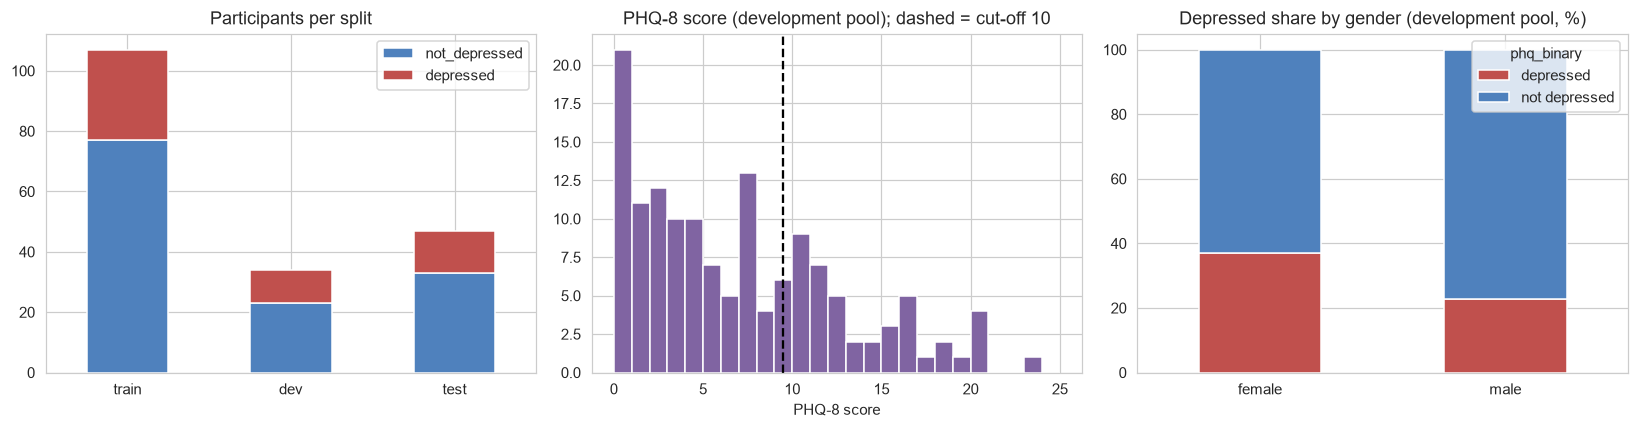

phq_binary,depressed,not depressed
gender,,
female,23,39
male,18,61


Gender × depression: chi² p = 0.095


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
tab[["not_depressed", "depressed"]].plot.bar(stacked=True, ax=axes[0], color=["#4f81bd", "#c0504d"], rot=0)
axes[0].set_title("Participants per split"); axes[0].set_xlabel("")
sc = labels.loc[DEVPOOL, "phq_score"]
axes[1].hist(sc, bins=range(0, 26), color="#8064a2", edgecolor="white"); axes[1].axvline(9.5, color="k", ls="--")
axes[1].set_title("PHQ-8 score (development pool); dashed = cut-off 10"); axes[1].set_xlabel("PHQ-8 score")
g = pd.crosstab(labels.loc[DEVPOOL, "gender"].map({0: "female", 1: "male"}), labels.loc[DEVPOOL, "phq_binary"].map({0: "not depressed", 1: "depressed"}))
(g.div(g.sum(1), axis=0) * 100).plot.bar(stacked=True, ax=axes[2], color=["#c0504d", "#4f81bd"], rot=0)
axes[2].set_title("Depressed share by gender (development pool, %)"); axes[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "08_1_labels.png", bbox_inches="tight"); plt.show()
display(g)
chi = stats.chi2_contingency(g)
print(f"Gender × depression: chi² p = {chi[1]:.3f}")

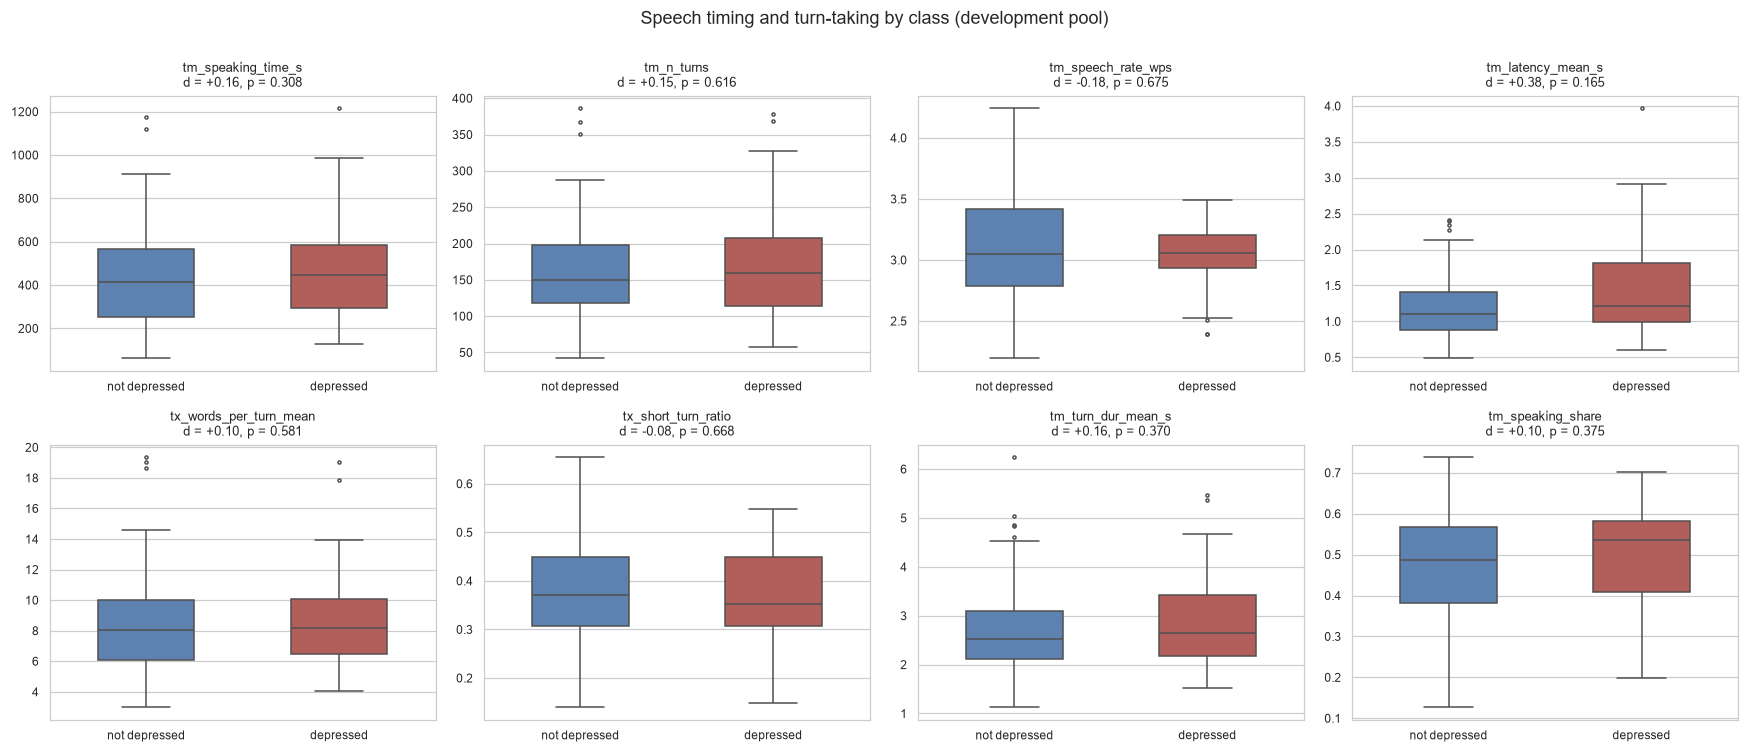

In [20]:
def by_class(cols, title, fname, ncols=4):
    cols = [c for c in cols if c in features.columns]
    n = len(cols); r = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(r, ncols, figsize=(4 * ncols, 3.4 * r))
    axes = np.atleast_1d(axes).ravel()
    dfp = features.loc[DEVPOOL, cols].assign(group=np.where(yD == 1, "depressed", "not depressed"))
    for ax, c in zip(axes, cols):
        sns.boxplot(data=dfp, x="group", y=c, ax=ax, order=["not depressed", "depressed"], palette=["#4f81bd", "#c0504d"], width=0.5, fliersize=2)
        d = rank.loc[c, "cohens_d"] if c in rank.index else np.nan
        p = rank.loc[c, "p_value"] if c in rank.index else np.nan
        ax.set_title(f"{c}\nd = {d:+.2f}, p = {p:.3f}", fontsize=8.5); ax.set_xlabel(""); ax.set_ylabel("")
        ax.tick_params(labelsize=8)
    for ax in axes[n:]:
        ax.axis("off")
    plt.suptitle(title, y=1.0); plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches="tight"); plt.show()

by_class(["tm_speaking_time_s", "tm_n_turns", "tm_speech_rate_wps", "tm_latency_mean_s",
          "tx_words_per_turn_mean", "tx_short_turn_ratio", "tm_turn_dur_mean_s", "tm_speaking_share"],
         "Speech timing and turn-taking by class (development pool)", "08_2_timing.png")

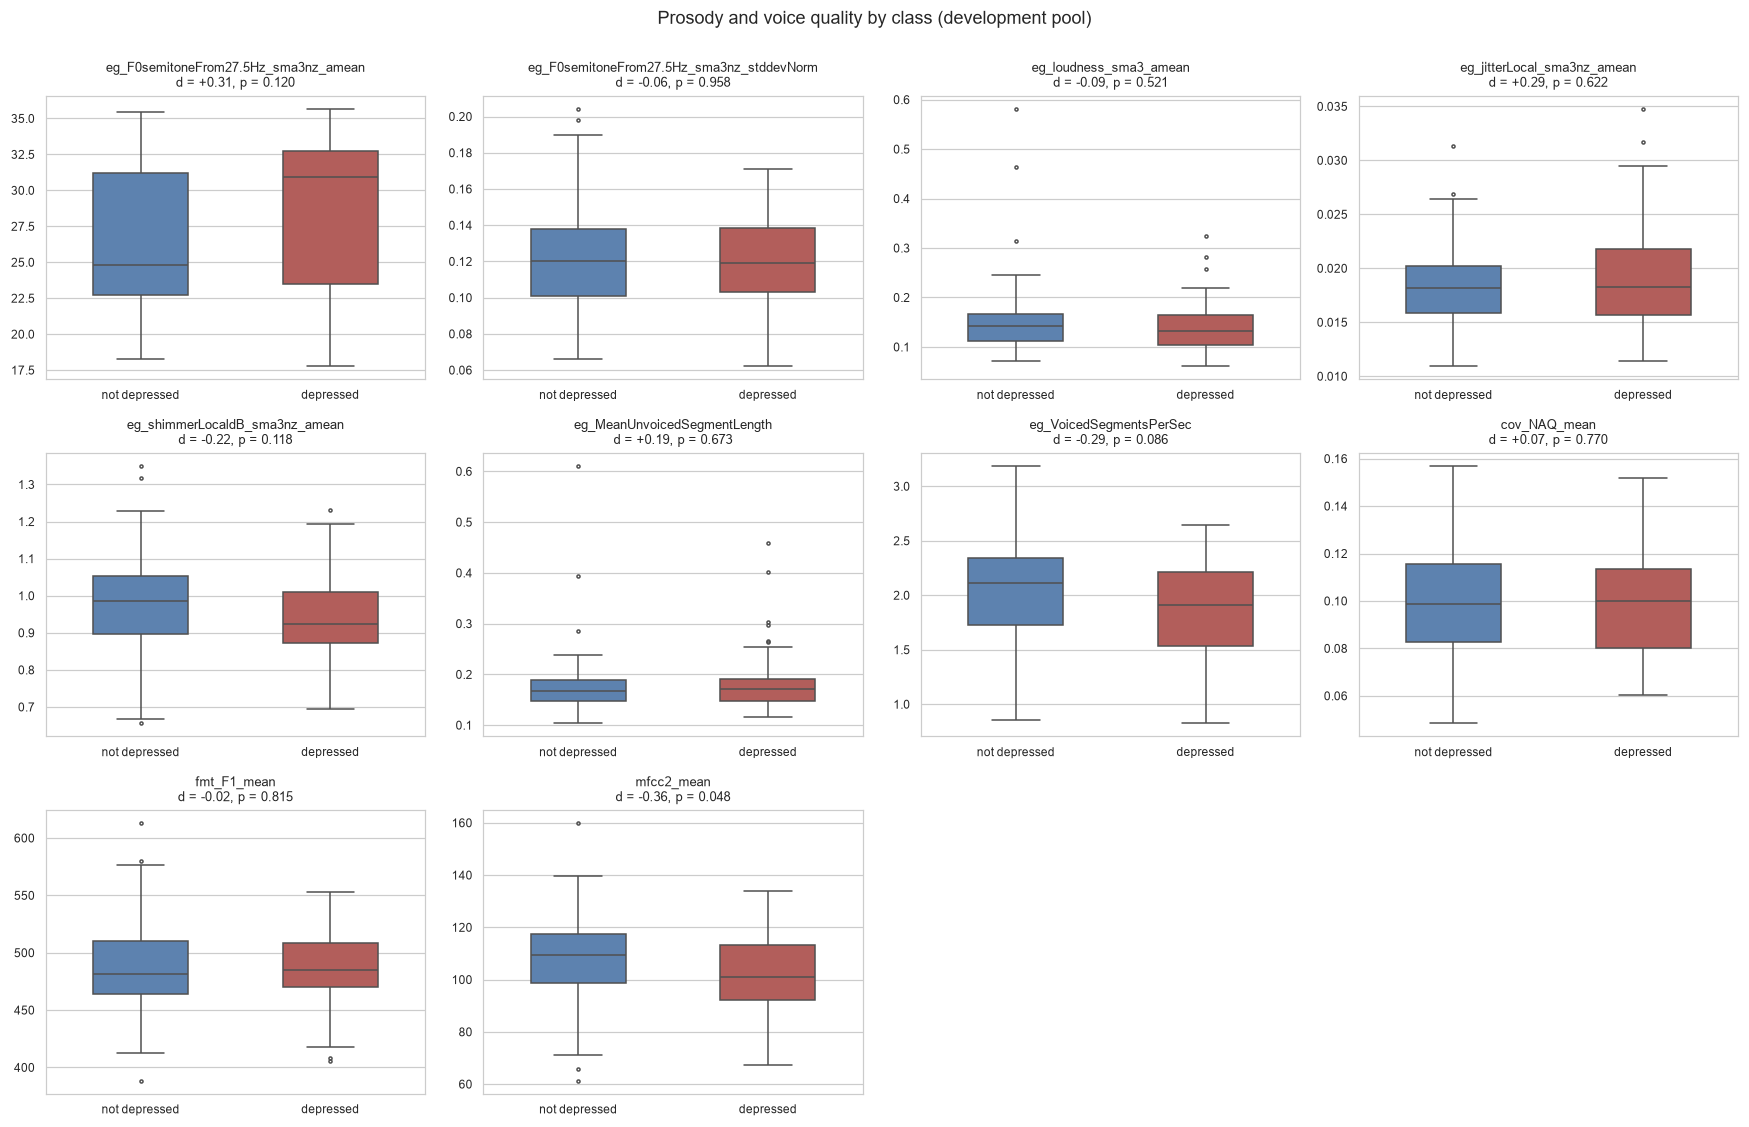

In [21]:
by_class(["eg_F0semitoneFrom27.5Hz_sma3nz_amean", "eg_F0semitoneFrom27.5Hz_sma3nz_stddevNorm", "eg_loudness_sma3_amean",
          "eg_jitterLocal_sma3nz_amean", "eg_shimmerLocaldB_sma3nz_amean", "eg_HNRdBACF_sma3nz_amean",
          "eg_MeanUnvoicedSegmentLength", "eg_VoicedSegmentsPerSec", "cov_NAQ_mean", "cov_creak_mean", "fmt_F1_mean", "mfcc2_mean"],
         "Prosody and voice quality by class (development pool)", "08_3_acoustic.png")

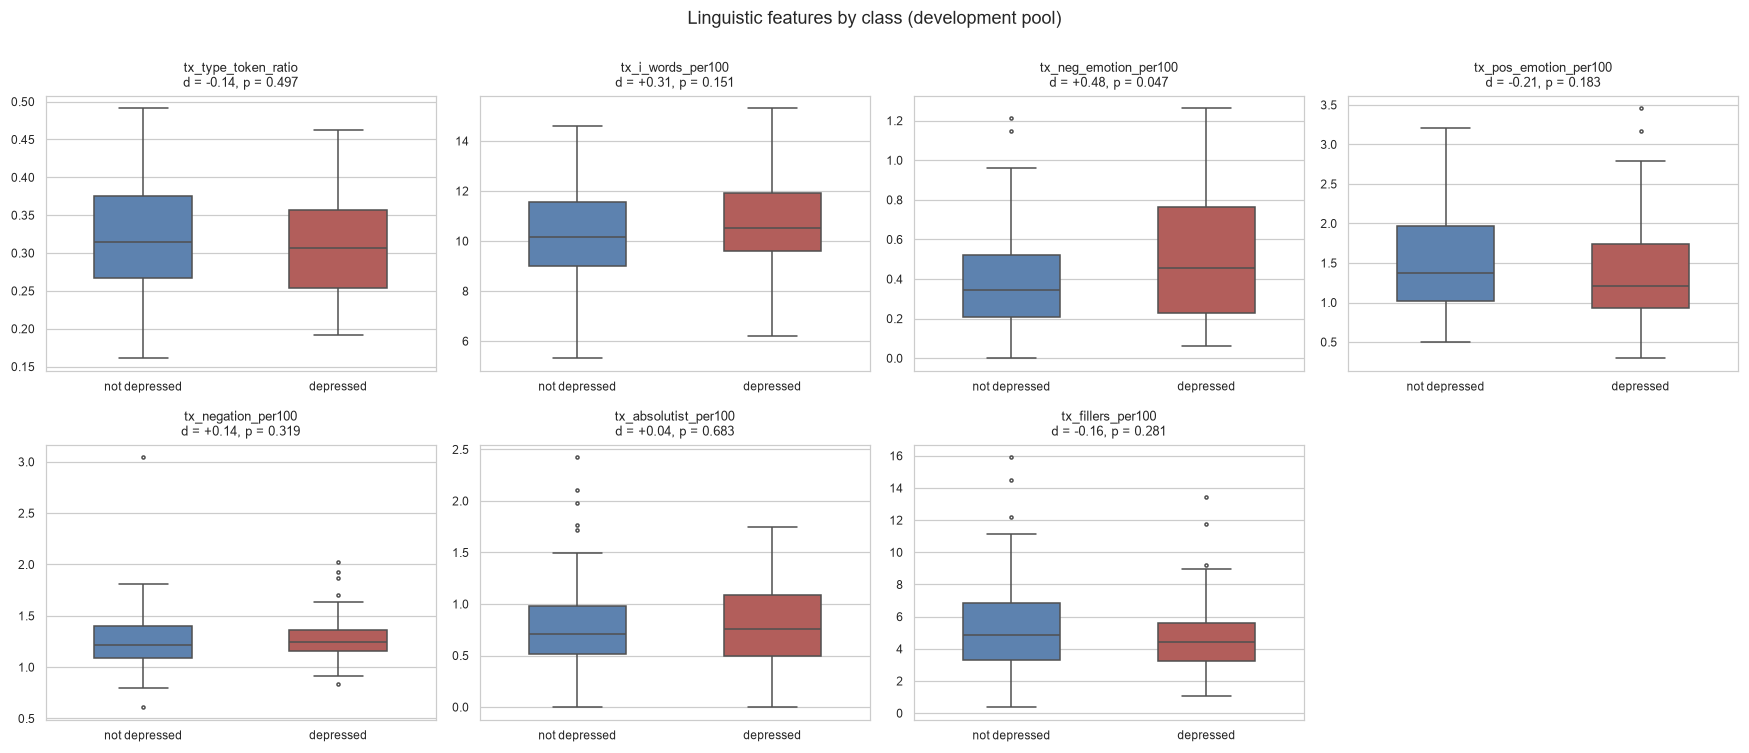

In [22]:
by_class(["tx_word_count", "tx_type_token_ratio", "tx_i_words_per100", "tx_neg_emotion_per100", "tx_pos_emotion_per100",
          "tx_negation_per100", "tx_absolutist_per100", "tx_fillers_per100"],
         "Linguistic features by class (development pool)", "08_4_linguistic.png")

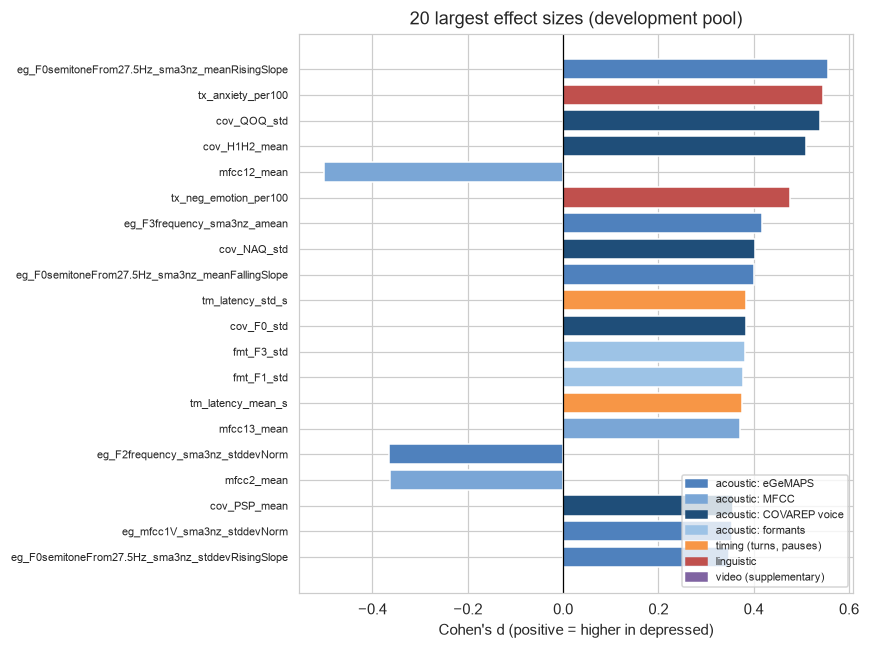

Strongest effect per block:


,block,cohens_d,p_value,q_value_BH
feature,,,,
eg_F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope,acoustic: eGeMAPS,0.556,0.021,0.811
tx_anxiety_per100,linguistic,0.546,0.013,0.629
cov_QOQ_std,acoustic: COVAREP voice,0.539,0.013,0.813
mfcc12_mean,acoustic: MFCC,-0.502,0.006,1.000
tm_latency_std_s,"timing (turns, pauses)",0.383,0.275,0.795
fmt_F3_std,acoustic: formants,0.381,0.050,0.638
vid_pose_Ty_std,video (supplementary),0.293,0.118,0.703


In [23]:
top = rank.head(20)
fig, ax = plt.subplots(figsize=(8, 6))
colors = {"acoustic: eGeMAPS": "#4f81bd", "acoustic: MFCC": "#7aa6d6", "acoustic: COVAREP voice": "#1f4e79",
          "acoustic: formants": "#9dc3e6", "timing (turns, pauses)": "#f79646", "linguistic": "#c0504d", "video (supplementary)": "#8064a2"}
ax.barh(top.index[::-1], top["cohens_d"][::-1], color=[colors.get(b, "grey") for b in top["block"][::-1]])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Cohen's d (positive = higher in depressed)")
ax.set_title("20 largest effect sizes (development pool)"); ax.tick_params(axis="y", labelsize=7.5)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "08_5_effect_sizes.png", bbox_inches="tight"); plt.show()
print("Strongest effect per block:")
display(rank.groupby("block").head(1)[["block", "cohens_d", "p_value", "q_value_BH"]].round(3))

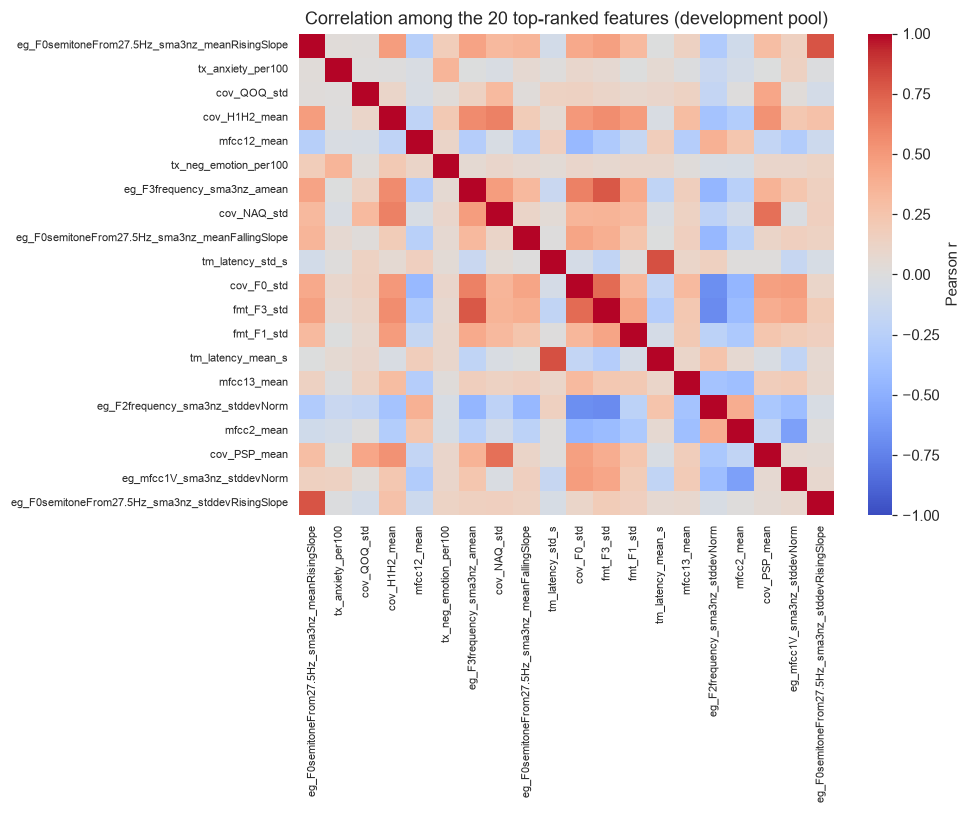

In [24]:
cm = features.loc[DEVPOOL, top.index].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("Correlation among the 20 top-ranked features (development pool)"); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "08_6_correlation.png", bbox_inches="tight"); plt.show()

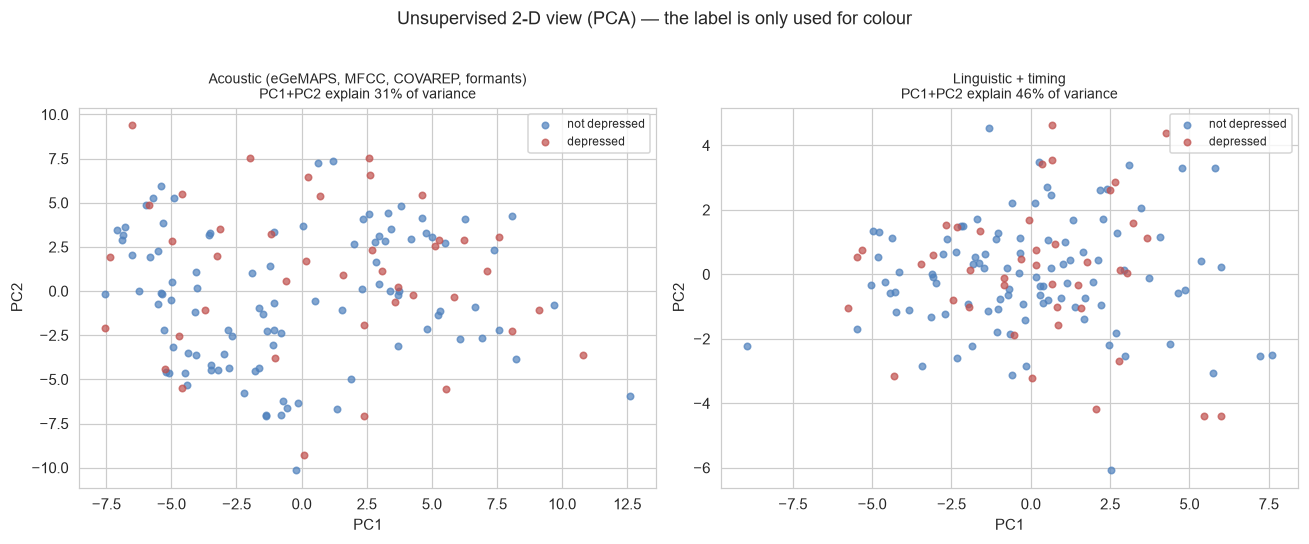

In [25]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
groups = {"Acoustic (eGeMAPS, MFCC, COVAREP, formants)": [c for b in BLOCKS if b.startswith("acoustic") for c in BLOCKS[b]],
          "Linguistic + timing": BLOCKS["linguistic"] + BLOCKS["timing (turns, pauses)"]}
for ax, (name, cols) in zip(axes, groups.items()):
    Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(features.loc[DEVPOOL, cols]))
    pca = PCA(2, random_state=SEED).fit(Z); P = pca.transform(Z)
    for lab, col, nm in [(0, "#4f81bd", "not depressed"), (1, "#c0504d", "depressed")]:
        ax.scatter(P[yD == lab, 0], P[yD == lab, 1], s=18, alpha=0.7, c=col, label=nm)
    ax.set_title(f"{name}\nPC1+PC2 explain {pca.explained_variance_ratio_[:2].sum():.0%} of variance", fontsize=9)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8)
plt.suptitle("Unsupervised 2-D view (PCA) — the label is only used for colour", y=1.02)
plt.tight_layout(); plt.savefig(FIG_DIR / "08_7_pca.png", bbox_inches="tight"); plt.show()

,share of features with KS p < 0.05
vs,
dev,0.042
test,0.010


(≈0.05 expected if the splits come from the same distribution)


,feature,vs,p
374,vid_gaze_y_1_mean,dev,0.0068
274,cov_Rd_mean,dev,0.0096
5,tm_interview_length_s,test,0.0229
378,vid_gaze_z_1_mean,dev,0.0244
258,cov_H1H2_mean,dev,0.0345
0,tm_n_turns,dev,0.0351


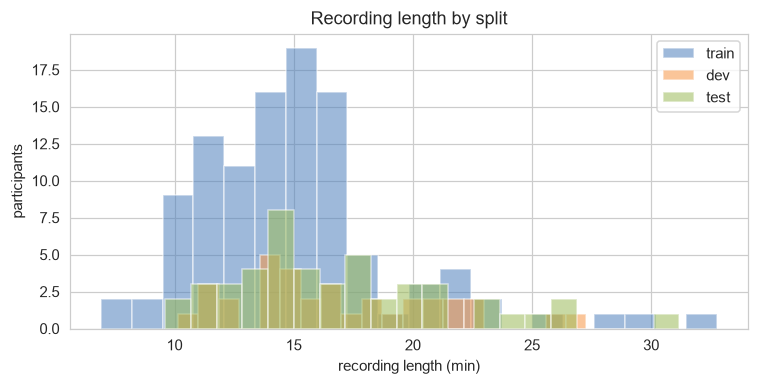

In [26]:
# Distribution shift between splits (labels not used): Kolmogorov–Smirnov test per feature
shift = []
for c in features.columns:
    a = features.loc[labels.index[labels.split == "train"], c].dropna()
    for s in ["dev", "test"]:
        b = features.loc[labels.index[labels.split == s], c].dropna()
        shift.append({"feature": c, "vs": s, "p": stats.ks_2samp(a, b).pvalue})
shift = pd.DataFrame(shift)
summary_shift = shift.groupby("vs")["p"].apply(lambda p: (p < 0.05).mean()).rename("share of features with KS p < 0.05")
display(summary_shift.round(3).to_frame())
print("(≈0.05 expected if the splits come from the same distribution)")
worst = shift.sort_values("p").head(6)
display(worst.round(4))

fig, ax = plt.subplots(figsize=(7, 3.6))
for s, col in [("train", "#4f81bd"), ("dev", "#f79646"), ("test", "#9bbb59")]:
    ax.hist(qc.loc[labels.index[labels.split == s], "audio_total_s"] / 60, bins=20, alpha=0.55, label=s, color=col)
ax.set_xlabel("recording length (min)"); ax.set_ylabel("participants"); ax.legend(); ax.set_title("Recording length by split")
plt.tight_layout(); plt.savefig(FIG_DIR / "08_8_split_shift.png", bbox_inches="tight"); plt.show()

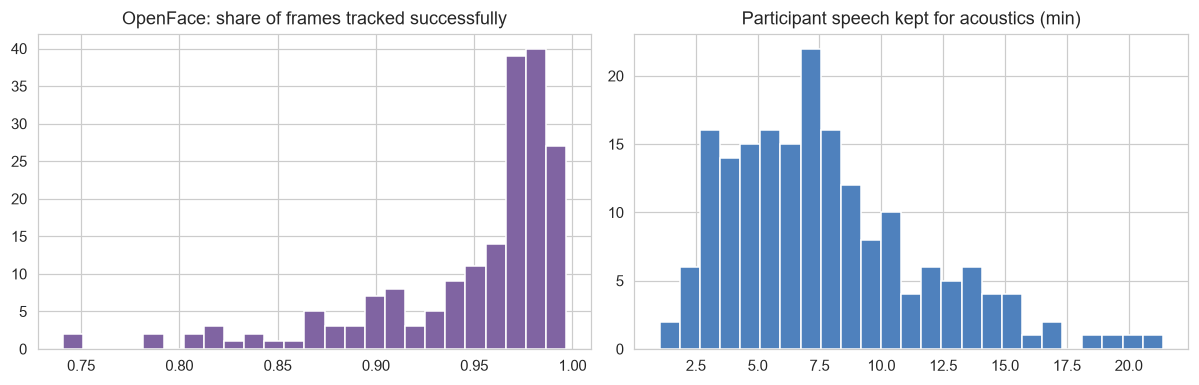

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(qc["video_success_rate"], bins=25, color="#8064a2"); axes[0].set_title("OpenFace: share of frames tracked successfully")
axes[1].hist(qc["audio_participant_s"] / 60, bins=25, color="#4f81bd"); axes[1].set_title("Participant speech kept for acoustics (min)")
plt.tight_layout(); plt.savefig(FIG_DIR / "08_9_quality.png", bbox_inches="tight"); plt.show()

## 9. Save Outputs

In [28]:
master = features.join(labels[["split"]])
master.to_csv(OUT_DIR / "features_master.csv")
print("features_master.csv:", master.shape, "→ one row per participant; columns = features + official split")
print("Labels are NOT stored in the feature file (join them from the split CSVs) to avoid accidental leakage.")

features_master.csv: (188, 192) → one row per participant; columns = features + official split
Labels are NOT stored in the feature file (join them from the split CSVs) to avoid accidental leakage.


## 10. Key Observations (computed)

The cell below prints the facts the written observations are based on, so every statement can be traced to a number in this run.

In [29]:
r = rank
def top_in(block_prefix, k=3):
    sub = r[r["block"].str.startswith(block_prefix)].head(k)
    return "; ".join(f"{i} (d={v:+.2f}, p={p:.3f})" for i, v, p in zip(sub.index, sub["cohens_d"], sub["p_value"]))
facts = {
    "participants with data": len(labels),
    "excluded (listed in split, no data)": excluded["participant_id"].tolist(),
    "development pool / test": f"{len(DEVPOOL)} / {(labels.pool == 'test').sum()}",
    "depressed share (dev pool)": f"{labels.loc[DEVPOOL, 'phq_binary'].mean():.1%}",
    "official label != (PHQ-8 >= 10)": [m["participant_id"] for m in mismatch] or "none",
    "recording length, min (median, range)": f"{qc['audio_total_s'].median() / 60:.1f} ({qc['audio_total_s'].min() / 60:.1f}–{qc['audio_total_s'].max() / 60:.1f})",
    "participant speech kept, min (median)": f"{qc['audio_participant_s'].median() / 60:.1f}",
    "participant turns (median, range)": f"{qc['participant_turns'].median():.0f} ({qc['participant_turns'].min():.0f}–{qc['participant_turns'].max():.0f})",
    "OpenFace success rate (median, min)": f"{qc['video_success_rate'].median():.3f}, {qc['video_success_rate'].min():.3f}",
    "final features": features.shape[1],
    "features p<0.05 / FDR q<0.10": f"{(r.p_value < 0.05).sum()} / {(r.q_value_BH < 0.10).sum()} of {len(r)}",
    "top timing features": top_in("timing"),
    "top linguistic features": top_in("linguistic"),
    "top acoustic features": top_in("acoustic"),
    "top video features": top_in("video"),
    "gender x depression chi2 p": f"{chi[1]:.3f}",
    "split shift (share KS p<0.05) dev/test": f"{summary_shift.get('dev', np.nan):.3f} / {summary_shift.get('test', np.nan):.3f}",
}
for k, v in facts.items():
    print(f"{k:42s}: {v}")
pd.Series(facts, dtype=str).to_csv(OUT_DIR / "eda_summary.csv")

participants with data                    : 188
excluded (listed in split, no data)       : [440]
development pool / test                   : 141 / 47
depressed share (dev pool)                : 29.1%
official label != (PHQ-8 >= 10)           : [409]
recording length, min (median, range)     : 15.2 (6.9–32.8)
participant speech kept, min (median)     : 7.1
participant turns (median, range)         : 154 (42–386)
OpenFace success rate (median, min)       : 0.970, 0.741
final features                            : 191
features p<0.05 / FDR q<0.10              : 14 / 0 of 191
top timing features                       : tm_latency_std_s (d=+0.38, p=0.275); tm_latency_mean_s (d=+0.38, p=0.165); tm_latency_median_s (d=+0.32, p=0.168)
top linguistic features                   : tx_anxiety_per100 (d=+0.55, p=0.013); tx_neg_emotion_per100 (d=+0.48, p=0.047); tx_i_words_per100 (d=+0.31, p=0.151)
top acoustic features                     : eg_F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope (d=+0.56, p

### 10.1 Dataset integrity
- **188 participants have data** (IDs 300–492). IDs 342, 394, 398 and 460 do not exist in the corpus. **Participant 440 is listed in the dev split but has no data**, so it is excluded, leaving dev with 34 participants.
- **Every one of the 188 folders contains all nine expected file types.** Two unexpected files were found and ignored: `._487_TRANSCRIPT.csv` (a 4 KB macOS metadata file, not a transcript) and `300_CLNF_hog.txt` (an extra face-appearance file that only participant 300 has).
- **Labels:** no missing labels, no duplicate IDs, and no participant appears in more than one split. The official binary label disagrees with the PHQ-8 ≥ 10 rule for exactly **one participant (409, score 10, labelled 0)**; we keep the official label. Participant 319 is missing one PHQ-8 item, which does not affect the total score or label.
- The pre-computed embedding tables cover exactly the same 188 participants, with no missing values or duplicate IDs.

### 10.2 Class balance and demographics
- **29 % of participants are depressed**: 41 of 141 in the development pool and 14 of 47 in the test split (≈ 2.4 : 1). Accuracy is therefore a misleading metric, which is why macro-F1 is primary.
- In the development pool, **37 % of women vs 23 % of men are depressed** (χ² p = 0.095). This is a notable but not significant difference. Gender is not used as an input, but it is a reason to check results by gender later.

### 10.3 Raw-file quality
- **COVAREP**: all 188 files have 74 numeric columns with no missing or non-numeric cells, and COVAREP and FORMANT frame counts agree to within one frame.
- **Transcripts**: the transcripts of **451, 458 and 480 contain only the participant's turns** (no Ellie rows). Their response latency is therefore undefined. These are the **only missing values in the whole feature table** (3 participants × 3 latency features). They will be imputed inside training folds in Part 2.
- **OpenFace**: median tracking success is 97 % of frames. Four participants are below 80 % (344, 389, 418, 432; lowest 74 %). Only successfully tracked frames were aggregated.
- **Audio**: recordings last 6.9–32.8 min (median 15.2). After keeping only the participant's turns, the median participant has **7.1 min of own speech**, and the minimum is about 1 min. No clipping was found.

### 10.4 Cleaning and transformation decisions
- Removed: 2 constant columns (COVAREP `creak` is zero for everyone) and 27 near-duplicate features (|r| > 0.95, e.g. COVAREP mean F0 duplicates eGeMAPS F0 percentiles). **Final matrix: 188 participants × 191 features.**
- Outliers are rare (1–3 % of participants per feature on average) and concentrated in variability features (`stddevNorm`). The participants with the most extreme values (308, 307, 305, 344) have complete, plausible recordings. Nothing indicates measurement error, so **no participant was removed**.
- 21 strongly right-skewed features (loudness, spectral flux, unvoiced-segment lengths, negation rate) were log-transformed.

### 10.5 What the EDA shows
- **No single feature separates the classes.** Only 14 of 191 features differ at p < 0.05, against about 10 expected by chance, and **none survive false-discovery-rate correction**. The PCA views show depressed and non-depressed participants heavily overlapping. So any signal is spread across many weak features, which is why Part 2 relies on multivariate models, fusion and in-fold feature selection.
- The **largest effects are medium-sized (Cohen's d ≈ 0.5)** and point in clinically sensible directions:
  - **Language**: depressed participants use more **anxiety words** (d = +0.55) and **negative-emotion words** (d = +0.48), and slightly more first-person singular words (d = +0.31, not significant).
  - **Voice quality**: higher **H1–H2** (breathier phonation, d = +0.51), more variable **quasi-open quotient** (d = +0.54) and **steeper rising pitch slopes** (d = +0.56).
  - **Timing**: depressed participants take somewhat **longer and more variable pauses before answering** (latency d ≈ +0.38, not significant). Speaking time, number of turns and speech rate barely differ (|d| ≤ 0.18).
- **Video features (supplementary)** show the weakest effects (largest |d| ≈ 0.29), consistent with the proposal's focus on speech and text.
- **The splits are comparable.** The share of features whose distribution differs between train and dev/test (KS p < 0.05) is 4.2 % and 1.0 %, both at or below the 5 % expected by chance.

### 10.6 Implications for Part 2
1. Use **macro-F1** and class weighting or SMOTE: about 29 % of participants are depressed.
2. **Impute** the three missing latency values **inside training folds**.
3. Expect modest performance from hand-crafted features alone, since each univariate effect is weak. Combining many features and modalities is necessary.
4. Label-based feature selection must stay **inside cross-validation**. With 191 features and no univariate effect surviving correction, selecting on the full data would produce optimistic results.